# FAA_CxER — exploration notebook

This is a thin, interactive companion to the CLI scripts in `scripts/`. It
exists for poking at the data and sanity-checking a figure inline — the
actual pipeline stages are meant to be run as scripts (see the top-level
README.md), not copy-pasted into notebook cells like the old FAA_EMNLP
notebooks did.

Run stage 3 (`python scripts/03_merge_cxer_labels.py`) at least once
before this notebook, so `data/predictions/FAA_multi_model_predictions_with_metrics_and_cxer.json`
exists.

In [11]:
# ! source /home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/.venv/bin/activate

! pip install jiwer matplotlib


  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.8 MB)
  Using cached kiwisolver-1.5.1-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (1.6 MB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached fonttools-4.65.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (5.3 MB)
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (325 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)


In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from faa_cxer.config import default_config, DEFAULT_MODEL_PAIRS
from faa_cxer.io_utils import load_json, load_records

cfg = default_config()
cfg

Config(data_dir=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/data'), outputs_dir=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/outputs'), normalized_predictions=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/data/predictions/FAA_multi_model_predictions_normalized.json'), predictions_with_metrics=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/data/predictions/FAA_multi_model_predictions_with_metrics.json'), metrics_summary_csv=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/data/predictions/FAA_metrics_summary.csv'), cxer_labels_root=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/data/cxer_labels'), predictions_with_metrics_and_cxer=PosixPath('/home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/data/predictions/FAA_multi_model_predictions_with_metrics_and_cxer.json'), judge_model='meta-llama/Llama-3.3-70B-Instruct')

## Load the merged dataset (stage 3 output)

In [3]:
data = load_json(cfg.predictions_with_metrics_and_cxer)
samples = data["samples"]
print(f"{len(samples)} samples, {len(data['corpus_metrics'])} scored ASR models")
data["corpus_metrics"]["FAA_Model"]

6364 samples, 12 scored ASR models


{'WER': 11.3583, 'BERTDist': 0.020084, 'SemDist': 0.000703, 'cxer': 0.2062}

## The headline result: WER drops far more than CxER

This is the 2x2 grouped bar chart from `scripts/07_make_comparison_plots.py`,
rendered inline instead of saved straight to a file.

/home/kairam42/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
2026-09-12 15:24:50.730985: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-12 15:24:50.742619: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered

✓ Saved: /home/kairam42/ASR-FAA/ASR_Finetuning/FAA_CxER/outputs/faa_pretrained_vs_finetuned.png


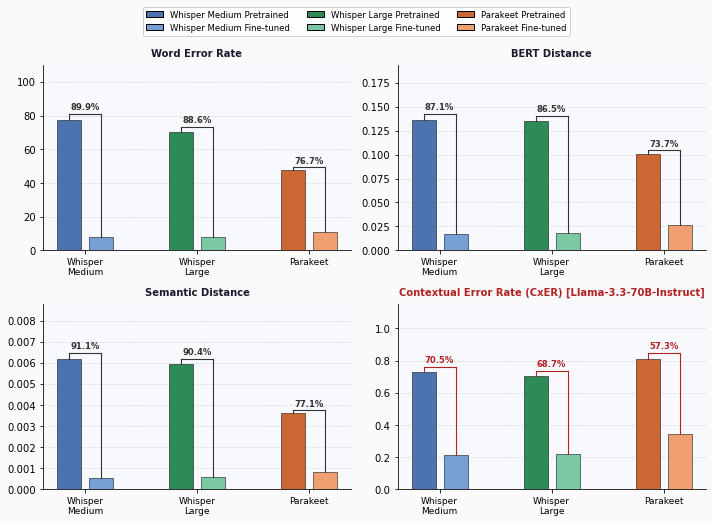

In [4]:
from faa_cxer.viz import ComparisonBarChart

chart = ComparisonBarChart(
    DEFAULT_MODEL_PAIRS,
    corpus_metrics=data["corpus_metrics"],
    corpus_cxer_metrics=data.get("corpus_cxer_metrics", {}),
)
chart.plot(str(cfg.outputs_dir / "faa_pretrained_vs_finetuned.png"), show=True)

## The paradox, sample by sample

`ParadoxAnalyzer` finds individual utterances with low WER (looks like a
great transcription) that the LLM judge still flagged as a critical,
operationally unsafe error.

In [5]:
from faa_cxer.analysis import ParadoxAnalyzer

analyzer = ParadoxAnalyzer(samples, judge=cfg.judge_short_name())
pair = DEFAULT_MODEL_PAIRS[0]  # Whisper Medium
rows = analyzer.get_model_records(pair.finetuned_key)
low_wer_critical = [
    r for r in rows
    if r["classification"] == "Critical_Errors" and r["WER"] is not None and r["WER"] < 0.1
]

print(f"{len(low_wer_critical)} samples with WER < 0.1 but a critical error")
for r in low_wer_critical[:5]:
    print()
    print(f"  WER={r['WER']:.3f}")
    print(f"  ref: {r['reference']}")
    print(f"  hyp: {r['hypothesis']}")

248 samples with WER < 0.1 but a critical error

  WER=0.042
  ref: delta seven twenty two turn left two six zero five from mattr three till established cleared the i l s runway two two right
  hyp: delta seven twenty two turn left two six zero five for mattr three till established cleared the i l s runway two two right

  WER=0.049
  ref: kalitta seven thirty cincinnati tower traffic eleven o'clock half a mile east bound appears to be a helicopter altitude indicates one thousand two hundred wind two zero zero at one two gusts one eight runway one eight center cleared to land
  hyp: kalitta seven thirty cincinnati tower traffic eleven o'clock half a mile east bound appears to be a helicopter altitude maintain one thousand two hundred wind two zero zero at one two gust one eight runway one eight center cleared to land

  WER=0.091
  ref: cleared to land two two left american twenty one ninety six
  hyp: cleared to land two two left american twenty one nine six

  WER=0.067
  ref: jetspe

## Next steps

- `scripts/04_analyze_token_frequency.py` — does fine-tuning help common
  words more than rare ones?
- `scripts/05_analyze_transitions.py` — the safety-drift transition matrix
  and Sankey diagram.
- `scripts/06_analyze_paradox.py` — the full concentration / trust-violation
  table and per-family scatter plots.

See the top-level README.md for the full pipeline explanation.